# Project UTS — Advanced Machine Learning
## Prediksi Nasabah Berlangganan Deposito Berjangka (`bank-full.csv`)

**Tujuan:** mencari kombinasi preprocessing, algoritma, dan hyperparameter terbaik.

| Bagian | Isi |
|---|---|
| 1 | Sumber data, target, metrik, temuan data → preprocessing |
| 2 | Split data, baseline, 3 model kandidat |
| 3 | Uji preprocessing & hyperparameter tuning (terpisah) |
| 4 | Pemilihan model terbaik & evaluasi data uji |

> Run penuh ± 15 menit (CPU 12 core). `random_state = 42` → hasil dapat direproduksi.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline          # Pipeline imblearn: mendukung langkah SMOTE
from imblearn.over_sampling import SMOTE
from scipy.stats import randint, uniform, loguniform

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)

RANDOM_STATE = 42
DATA_PATH = "bank-full.csv"

# Warna tetap per model (palet kategorikal yang aman untuk buta warna)
WARNA = {"Baseline (LogReg)": "#8a8985", "KNN": "#2a78d6", "Random Forest": "#eb6834", "XGBoost": "#1baf7a"}
ABU, TEKS = "#b9b8b3", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
})

---
## 1. Memahami Data, Target, dan Metrik

### 1.1 Sumber data & kamus data

**Sumber:** dataset publik **Bank Marketing**, UCI Machine Learning Repository (ID 222): https://archive.ics.uci.edu/dataset/222/bank+marketing · DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306) · lisensi CC BY 4.0.

- Telemarketing sebuah bank di Portugal, **Mei 2008 – Nov 2010**, baris urut menurut tanggal.
- `bank-full.csv` dari drive dosen **identik** dengan file resmi UCI (SHA-256 sama: `d1513ec6…849ed32d`).
- Keterangan kolom dari file resmi `bank-names.txt` (di dalam `bank.zip`).

**Referensi:**
1. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
2. Moro, S., Laureano, R., & Cortez, P. (2011). Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology. *Proc. European Simulation and Modelling Conference (ESM'2011)*, 117–121.
3. Moro, S., Cortez, P., & Rita, P. (2014). A Data-Driven Approach to Predict the Success of Bank Telemarketing. *Decision Support Systems*, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

**Kamus data** (16 fitur + 1 target):

| # | Kolom | Tipe | Keterangan |
|---|---|---|---|
| 1 | `age` | numerik | Umur nasabah |
| 2 | `job` | kategorikal | Jenis pekerjaan (admin., blue-collar, management, technician, services, retired, student, …, unknown) |
| 3 | `marital` | kategorikal | Status pernikahan: married, single, divorced (cerai/janda/duda) |
| 4 | `education` | kategorikal | Pendidikan: primary, secondary, tertiary, unknown |
| 5 | `default` | biner | Punya kredit macet? |
| 6 | `balance` | numerik | Rata-rata saldo tahunan (euro) |
| 7 | `housing` | biner | Punya kredit rumah? |
| 8 | `loan` | biner | Punya pinjaman pribadi? |
| 9 | `contact` | kategorikal | Jenis kontak: cellular, telephone, unknown |
| 10 | `day` | numerik | Tanggal kontak terakhir (1–31) |
| 11 | `month` | kategorikal | Bulan kontak terakhir (jan–dec) |
| 12 | `duration` | numerik | Durasi kontak terakhir (detik) |
| 13 | `campaign` | numerik | Jumlah kontak selama kampanye ini (termasuk kontak terakhir) |
| 14 | `pdays` | numerik | Hari sejak terakhir dihubungi di kampanye sebelumnya; −1 = belum pernah |
| 15 | `previous` | numerik | Jumlah kontak sebelum kampanye ini |
| 16 | `poutcome` | kategorikal | Hasil kampanye sebelumnya: success, failure, other, unknown |
| 17 | **`y`** | biner | **Target:** berlangganan deposito berjangka? (yes/no) |

Kelompok kolom: 1–8 data nasabah · 9–12 kontak terakhir · 13–16 riwayat kampanye.

> **Catatan resmi pembuat dataset** (`bank-additional-names.txt`) tentang `duration`: *"should be discarded if the intention is to have a realistic predictive model"* → dibuang (Bagian 2.2).

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")      # pemisah kolom pada file ini adalah titik koma
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
info = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "jumlah unik": df.nunique(),
    "missing (NaN)": df.isna().sum(),
    "nilai 'unknown'": (df == "unknown").sum(),
})
info["% unknown"] = (info["nilai 'unknown'"] / len(df) * 100).round(1)
print("Jumlah baris duplikat:", df.duplicated().sum())
info

Jumlah baris duplikat: 0


,tipe,jumlah unik,missing (NaN),nilai 'unknown',% unknown
age,int64,77,0,0,0.0
job,str,12,0,288,0.6
marital,str,3,0,0,0.0
education,str,4,0,1857,4.1
default,str,2,0,0,0.0
balance,int64,7168,0,0,0.0
housing,str,2,0,0,0.0
loan,str,2,0,0,0.0
contact,str,3,0,13020,28.8
day,int64,31,0,0,0.0


### 1.2 Target dan jenis masalah
- **Target:** `y` → 1 = yes, 0 = no.
- **Jenis masalah:** klasifikasi biner (supervised).

,jumlah,proporsi
y,,
no,39922,0.883
yes,5289,0.117


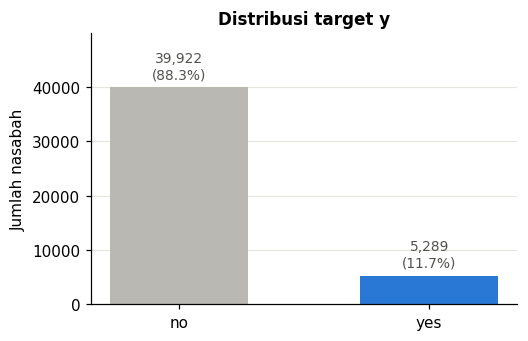

In [4]:
jumlah = df["y"].value_counts()
proporsi = df["y"].value_counts(normalize=True)
display(pd.DataFrame({"jumlah": jumlah, "proporsi": proporsi.round(3)}))

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(jumlah.index, jumlah.values, color=[ABU, WARNA["KNN"]], width=0.55)
for i, (n, p) in enumerate(zip(jumlah.values, proporsi.values)):
    ax.annotate(f"{n:,}\n({p:.1%})", (i, n), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, color=TEKS)
ax.set_title("Distribusi target y")
ax.set_ylabel("Jumlah nasabah")
ax.set_ylim(0, jumlah.max() * 1.25)
ax.grid(axis="x", visible=False)
plt.show()

### 1.3 Metrik evaluasi
Hanya **11,7%** `yes` → kelas tidak seimbang (± 1 : 7,5).

- **Akurasi tidak dipakai**: selalu menebak `no` sudah dapat 88,3%.
- **Metrik utama: PR-AUC** (Average Precision kelas `yes`): fokus ke kelas minoritas, tanpa threshold, nilai acak = 0,117.
- **Pendukung:** ROC-AUC, F1, Precision, Recall. Threshold akhir dipilih dari data validasi, bukan data uji.

### 1.4 Eksplorasi data

In [5]:
kolom_numerik = df.select_dtypes(include="number").columns.tolist()
ringkas = df[kolom_numerik].describe().T
ringkas["skewness"] = df[kolom_numerik].skew()
ringkas.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,0.68
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,8.36
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,0.09
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0,3.14
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0,4.90
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0,2.62
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0,41.85


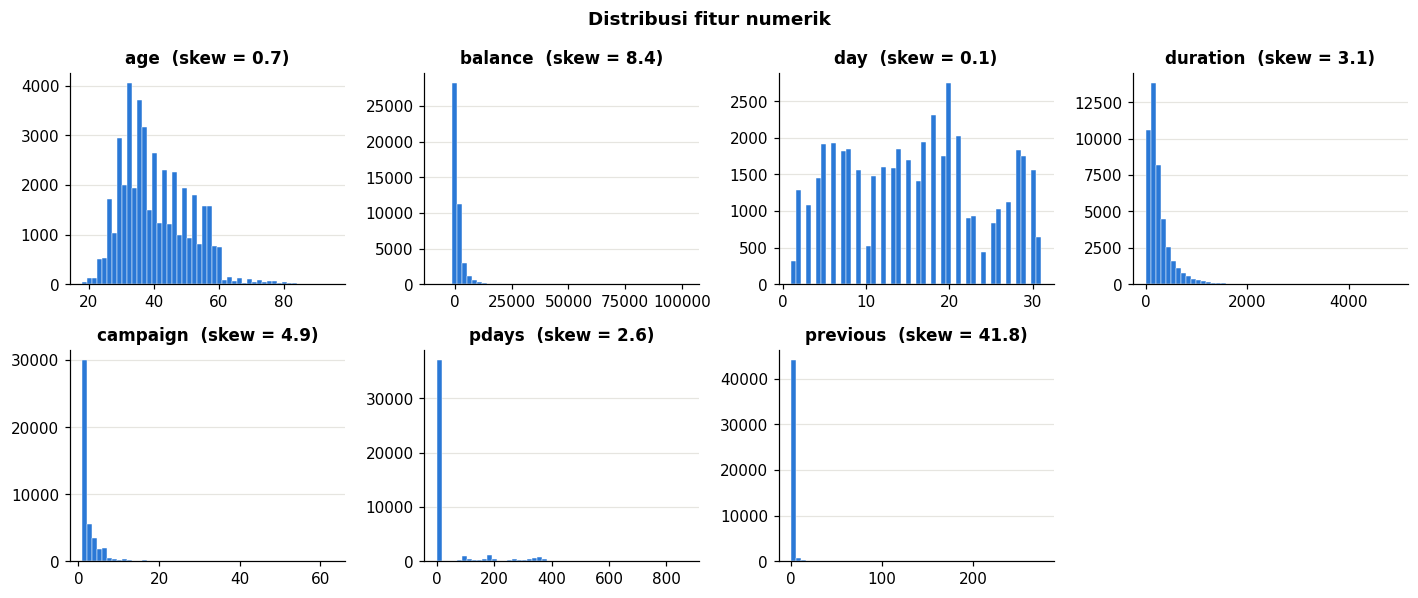

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, kol in zip(axes.flat, kolom_numerik):
    ax.hist(df[kol], bins=50, color=WARNA["KNN"], edgecolor="white", linewidth=0.3)
    ax.set_title(f"{kol}  (skew = {df[kol].skew():.1f})")
    ax.grid(axis="x", visible=False)
axes.flat[-1].axis("off")
fig.suptitle("Distribusi fitur numerik", fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
belum_dihubungi = df["pdays"] == -1
print(f"pdays = -1 (belum pernah dihubungi di kampanye sebelumnya): {belum_dihubungi.mean():.1%} baris")
print(f"pdays = -1 selalu bersamaan dengan previous = 0         : {(belum_dihubungi == (df['previous'] == 0)).all()}")
print(f"Saldo (balance) negatif                                 : {(df['balance'] < 0).mean():.1%} baris")
print(f"Rentang balance: {df['balance'].min():,} s.d. {df['balance'].max():,}  |  rentang campaign: {df['campaign'].min()} s.d. {df['campaign'].max()}")

pdays = -1 (belum pernah dihubungi di kampanye sebelumnya): 81.7% baris
pdays = -1 selalu bersamaan dengan previous = 0         : True
Saldo (balance) negatif                                 : 8.3% baris
Rentang balance: -8,019 s.d. 102,127  |  rentang campaign: 1 s.d. 63


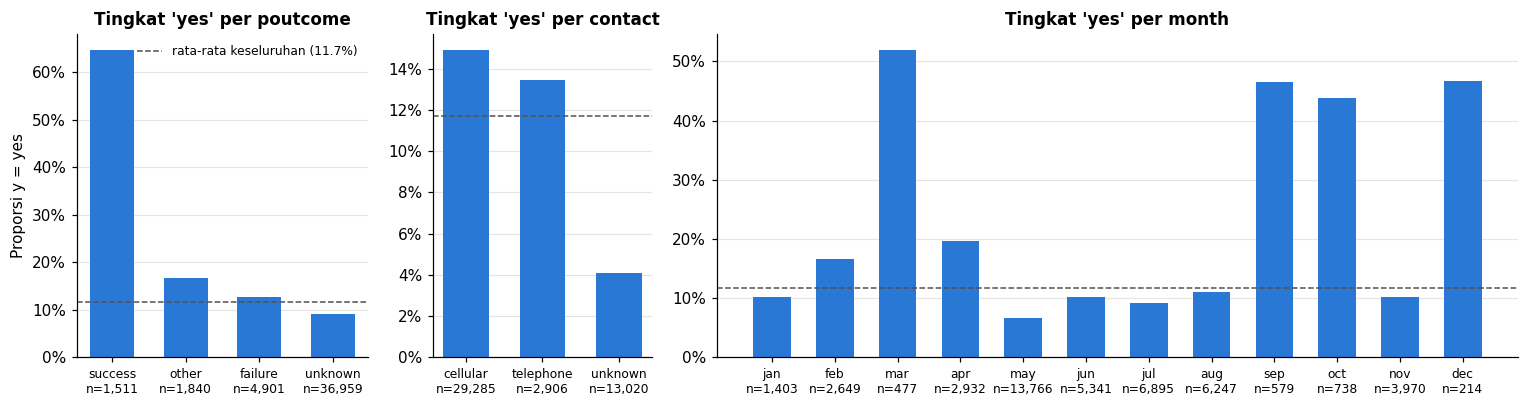

In [8]:
rata2_yes = (df["y"] == "yes").mean()
urutan_bulan = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [4, 3, 11]})
for ax, kol in zip(axes, ["poutcome", "contact", "month"]):
    tingkat = df.groupby(kol)["y"].apply(lambda s: (s == "yes").mean())
    n = df[kol].value_counts()
    urutan = urutan_bulan if kol == "month" else tingkat.sort_values(ascending=False).index
    tingkat, n = tingkat.reindex(urutan), n.reindex(urutan)
    ax.bar(range(len(tingkat)), tingkat.values, color=WARNA["KNN"], width=0.6)
    ax.axhline(rata2_yes, color=TEKS, ls="--", lw=1)
    ax.set_xticks(range(len(tingkat)), [f"{k}\nn={v:,}" for k, v in zip(tingkat.index, n.values)], fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(f"Tingkat 'yes' per {kol}")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Proporsi y = yes")
axes[0].legend([Line2D([0], [0], color=TEKS, ls="--", lw=1)], [f"rata-rata keseluruhan ({rata2_yes:.1%})"], loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
print("Statistik duration (detik) per kelas target:")
display(df.groupby("y")["duration"].describe().round(1))
nol = df["duration"] == 0
print(f"Panggilan dengan duration = 0: {nol.sum()} baris → semuanya y = {df.loc[nol, 'y'].unique().tolist()}")

Statistik duration (detik) per kelas target:


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,221.2,207.4,0.0,95.0,164.0,279.0,4918.0
yes,5289.0,537.3,392.5,8.0,244.0,426.0,725.0,3881.0


Panggilan dengan duration = 0: 3 baris → semuanya y = ['no']


### 1.5 Temuan → keputusan preprocessing

| Temuan | Keputusan |
|---|---|
| Kelas tidak seimbang (11,7% `yes`) | Split stratified, PR-AUC, uji SMOTE |
| Tidak ada NaN/duplikat; ada `unknown` (contact 28,8%, poutcome 81,7%) yang informatif | `unknown` = kategori sendiri |
| 9 fitur kategorikal nominal | One-hot encoding |
| Skala numerik sangat berbeda (balance −8.019 s.d. 102.127) | Uji standardisasi |
| balance, campaign, previous, pdays sangat miring (skew 2,6–41,8) | Uji transformasi log |
| `pdays = −1` = kode "belum pernah dihubungi" (81,7%) | Uji flag `pernah_dihubungi` |
| `poutcome = success` → 64,7% `yes`; mar/sep/oct/dec > 40% | Dipertahankan |
| `duration` baru diketahui setelah telepon | Dibuang (leakage, Bagian 2.2) |
| 50–51 fitur setelah one-hot | Uji seleksi fitur (mutual information) |

---
## 2. Pembagian Data, Baseline, dan Model Kandidat
- Data uji **20%** disisihkan sejak awal (stratified), dipakai sekali di Bagian 4.
- Semua model: **5-fold stratified CV** pada data latih, fold & metrik sama.
- Preprocessing di dalam **Pipeline** → hanya di-fit pada fold latih (tanpa kebocoran).

In [10]:
y_all = (df["y"] == "yes").astype(int)
X_all = df.drop(columns=["y"])

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)

# duration dibuang (lihat 1.5); versi *_full hanya dipakai untuk membuktikan kebocorannya di 2.2
X_train = X_train_full.drop(columns=["duration"])
X_test = X_test_full.drop(columns=["duration"])

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Data latih: {X_train.shape[0]:,} baris, {X_train.shape[1]} fitur, proporsi yes = {y_train.mean():.3f}")
print(f"Data uji  : {X_test.shape[0]:,} baris, {X_test.shape[1]} fitur, proporsi yes = {y_test.mean():.3f}")

Data latih: 36,168 baris, 15 fitur, proporsi yes = 0.117
Data uji  : 9,043 baris, 15 fitur, proporsi yes = 0.117


### 2.1 Fungsi pembantu
`[rekayasa fitur] → one-hot (+ scaling) → [seleksi fitur] → [SMOTE] → model`, tiap opsi bisa dinyalakan satu per satu.

In [11]:
def rekayasa_fitur(X):
    # Transformasi fitur numerik yang miring + flag pdays (aktif bila transform=True)
    X = X.copy()
    X["pernah_dihubungi"] = (X["pdays"] != -1).astype(int)
    X["pdays"] = np.log1p(X["pdays"].replace(-1, 999))                 # -1 = belum pernah → dianggap "sangat lama"
    X["balance"] = np.sign(X["balance"]) * np.log1p(X["balance"].abs())  # signed-log karena ada saldo negatif
    X["campaign"] = np.log1p(X["campaign"])
    X["previous"] = np.log1p(X["previous"])
    return X


def skor_mutual_info(X, y):
    # Mutual information; kolom biner hasil one-hot dihitung sebagai fitur diskrit
    X = np.asarray(X)
    diskrit = np.array([np.isin(np.unique(X[:, j]), [0, 1]).all() for j in range(X.shape[1])])
    return mutual_info_classif(X, y, discrete_features=diskrit, random_state=RANDOM_STATE)


def buat_pipeline(model, scaling=False, transform=False, k_fitur=None, smote=False):
    langkah = []
    if transform:
        langkah.append(("rekayasa", FunctionTransformer(rekayasa_fitur)))
    langkah.append(("encode", ColumnTransformer([
        ("num", StandardScaler() if scaling else "passthrough", make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), make_column_selector(dtype_exclude="number")),
    ])))
    if k_fitur:
        langkah.append(("seleksi", SelectKBest(skor_mutual_info, k=k_fitur)))
    if smote:
        langkah.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    langkah.append(("model", model))
    return Pipeline(langkah)


SCORING = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1",
           "Precision": "precision", "Recall": "recall"}


def evaluasi_cv(pipeline, X=None, y=None):
    # 5-fold CV pada data latih (fold sama untuk semua model); rata-rata tiap metrik + std PR-AUC
    X = X_train if X is None else X
    y = y_train if y is None else y
    hasil = cross_validate(pipeline, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    skor = {m: hasil[f"test_{m}"].mean() for m in SCORING}
    skor["PR-AUC std"] = hasil["test_PR-AUC"].std()
    return skor

### 2.2 Bukti kebocoran `duration`
Logistic Regression yang sama, tanpa vs dengan `duration` (CV data latih).

In [12]:
lr = LogisticRegression(max_iter=2000)
bukti_leakage = pd.DataFrame({
    "tanpa duration": evaluasi_cv(buat_pipeline(lr, scaling=True), X_train, y_train),
    "dengan duration": evaluasi_cv(buat_pipeline(lr, scaling=True), X_train_full, y_train),
}).T[["PR-AUC", "ROC-AUC", "F1"]]
bukti_leakage

,PR-AUC,ROC-AUC,F1
tanpa duration,0.4021,0.7628,0.2749
dengan duration,0.5535,0.9066,0.4503


**Hasil:** PR-AUC 0,402 → **0,553**, ROC-AUC 0,763 → **0,907**. Skor naik karena `duration` sudah "mengandung jawaban" (median 426 vs 164 detik), padahal baru diketahui setelah telepon → **dibuang**, sesuai catatan resmi pembuat dataset.

### 2.3 Baseline dan tiga model kandidat
- **Dummy** (referensi): menebak proporsi kelas.
- **Baseline:** Logistic Regression (one-hot + scaling).
- **Kandidat:** KNN (berbasis jarak), Random Forest (bagging), XGBoost (boosting).

Konfigurasi awal kandidat: hyperparameter default, one-hot saja.

In [13]:
MODEL_KANDIDAT = {
    "KNN": lambda: KNeighborsClassifier(),
    "Random Forest": lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": lambda: XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric="logloss"),
}

pipeline_baseline = buat_pipeline(LogisticRegression(max_iter=2000), scaling=True)

hasil_awal = {
    "Dummy (referensi)": evaluasi_cv(buat_pipeline(DummyClassifier(strategy="prior"))),
    "Baseline (LogReg)": evaluasi_cv(pipeline_baseline),
}
for nama, buat_model in MODEL_KANDIDAT.items():
    hasil_awal[nama] = evaluasi_cv(buat_pipeline(buat_model()))

tabel_awal = pd.DataFrame(hasil_awal).T
tabel_awal

,PR-AUC,ROC-AUC,F1,Precision,Recall,PR-AUC std
Dummy (referensi),0.1170,0.5000,0.0000,0.0000,0.0000,5.2560e-05
Baseline (LogReg),0.4021,0.7628,0.2749,0.6446,0.1749,8.3763e-03
KNN,0.1824,0.6108,0.1598,0.3697,0.1023,4.7923e-03
Random Forest,0.4115,0.7789,0.3271,0.5978,0.2252,1.5911e-02
XGBoost,0.4252,0.7841,0.3632,0.5838,0.2638,1.3997e-02


**Pengamatan:**
- Dummy 0,117 = tebakan acak; baseline LogReg **0,402**.
- Random Forest (0,412) dan XGBoost (0,425) sedikit di atas baseline.
- KNN (0,182) jauh di bawah: jarak didominasi `balance` yang belum di-scale.
- Recall pada threshold 0,5 rendah (10–26%) → threshold diatur ulang di 4.2.

---
## 3. Uji Preprocessing dan Hyperparameter Tuning
Dilakukan **terpisah**: preprocessing dulu (hyperparameter default), lalu tuning (preprocessing dikunci).

### 3.1 Uji preprocessing
Satu perubahan per langkah, dibandingkan dengan konfigurasi terbaik saat itu. **Dipakai** jika PR-AUC naik > 0,002; jika tidak, **dibatalkan**.

| Langkah | Perubahan | Dasar |
|---|---|---|
| P1 | Standardisasi (StandardScaler) | Skala berbeda jauh |
| P2 | Log fitur miring + flag `pernah_dihubungi` | Skew tinggi, `pdays = −1` |
| P3 | Seleksi fitur MI, k ∈ {20, 30, 40} | Fitur redundan |
| P4 | SMOTE (fold latih saja) | Kelas tidak seimbang |

In [14]:
LANGKAH_PREPROCESSING = [
    ("P1", "Standardisasi fitur numerik", [{"scaling": True}]),
    ("P2", "Transformasi log + flag pernah_dihubungi", [{"transform": True}]),
    ("P3", "Seleksi fitur (mutual information)", [{"k_fitur": k} for k in (20, 30, 40)]),
    ("P4", "SMOTE pada data latih", [{"smote": True}]),
]
MIN_KENAIKAN = 0.002


def uji_preprocessing(nama_model, buat_model):
    config = dict(scaling=False, transform=False, k_fitur=None, smote=False)
    skor_saat_ini = hasil_awal[nama_model]           # konfigurasi awal (Bagian 2.3)
    baris = []
    for kode, perubahan, daftar_opsi in LANGKAH_PREPROCESSING:
        # coba semua opsi pada langkah ini (P3: beberapa nilai k) lalu ambil yang terbaik
        percobaan = []
        for opsi in daftar_opsi:
            cfg = {**config, **opsi}
            percobaan.append((opsi, cfg, evaluasi_cv(buat_pipeline(buat_model(), **cfg))))
        opsi, cfg, skor = max(percobaan, key=lambda t: t[2]["PR-AUC"])
        delta = skor["PR-AUC"] - skor_saat_ini["PR-AUC"]
        dipakai = delta > MIN_KENAIKAN
        baris.append({
            "Model": nama_model, "Langkah": kode,
            "Perubahan": perubahan + (f" (k={opsi['k_fitur']})" if "k_fitur" in opsi else ""),
            "PR-AUC sebelum": skor_saat_ini["PR-AUC"], "PR-AUC sesudah": skor["PR-AUC"], "Δ PR-AUC": delta,
            "ROC-AUC sesudah": skor["ROC-AUC"], "F1 sesudah": skor["F1"],
            "Keputusan": "dipakai ✓" if dipakai else "tidak dipakai ✗",
            "Detail": ", ".join(f"k={o['k_fitur']}: {s['PR-AUC']:.4f}" for o, _, s in percobaan) if len(percobaan) > 1 else "",
        })
        if dipakai:
            config, skor_saat_ini = cfg, skor
    return pd.DataFrame(baris), config, skor_saat_ini


daftar_tabel, config_terbaik, skor_prepro = [], {}, {}
for nama, buat_model in MODEL_KANDIDAT.items():
    t0 = time.time()
    tabel, config, skor = uji_preprocessing(nama, buat_model)
    daftar_tabel.append(tabel)
    config_terbaik[nama], skor_prepro[nama] = config, skor
    print(f"{nama:14s} selesai dalam {time.time() - t0:4.0f} detik → preprocessing terpilih: {config}")

tabel_prepro = pd.concat(daftar_tabel, ignore_index=True)
tabel_prepro

KNN            selesai dalam   23 detik → preprocessing terpilih: {'scaling': True, 'transform': True, 'k_fitur': None, 'smote': False}
Random Forest  selesai dalam   31 detik → preprocessing terpilih: {'scaling': False, 'transform': True, 'k_fitur': None, 'smote': False}
XGBoost        selesai dalam    9 detik → preprocessing terpilih: {'scaling': False, 'transform': False, 'k_fitur': None, 'smote': True}


,Model,Langkah,Perubahan,PR-AUC sebelum,PR-AUC sesudah,Δ PR-AUC,ROC-AUC sesudah,F1 sesudah,Keputusan,Detail
0,KNN,P1,Standardisasi fitur numerik,0.1824,0.2817,0.0993,0.6910,0.2944,dipakai ✓,
1,KNN,P2,Transformasi log + flag pernah_dihubungi,0.2817,0.2866,0.0049,0.6940,0.3096,dipakai ✓,
2,KNN,P3,Seleksi fitur (mutual information) (k=30),0.2866,0.2699,-0.0167,0.6892,0.2763,tidak dipakai ✗,"k=20: 0.2617, k=30: 0.2699, k=40: 0.2683"
3,KNN,P4,SMOTE pada data latih,0.2866,0.2436,-0.0430,0.7046,0.3363,tidak dipakai ✗,
4,Random Forest,P1,Standardisasi fitur numerik,0.4115,0.4109,-0.0006,0.7787,0.3265,tidak dipakai ✗,
5,Random Forest,P2,Transformasi log + flag pernah_dihubungi,0.4115,0.4147,0.0032,0.7781,0.3264,dipakai ✓,
6,Random Forest,P3,Seleksi fitur (mutual information) (k=40),0.4147,0.4070,-0.0077,0.7725,0.3250,tidak dipakai ✗,"k=20: 0.3762, k=30: 0.4017, k=40: 0.4070"
7,Random Forest,P4,SMOTE pada data latih,0.4147,0.4008,-0.0139,0.7706,0.3595,tidak dipakai ✗,
8,XGBoost,P1,Standardisasi fitur numerik,0.4252,0.4252,0.0000,0.7841,0.3632,tidak dipakai ✗,
9,XGBoost,P2,Transformasi log + flag pernah_dihubungi,0.4252,0.4232,-0.0020,0.7845,0.3563,tidak dipakai ✗,


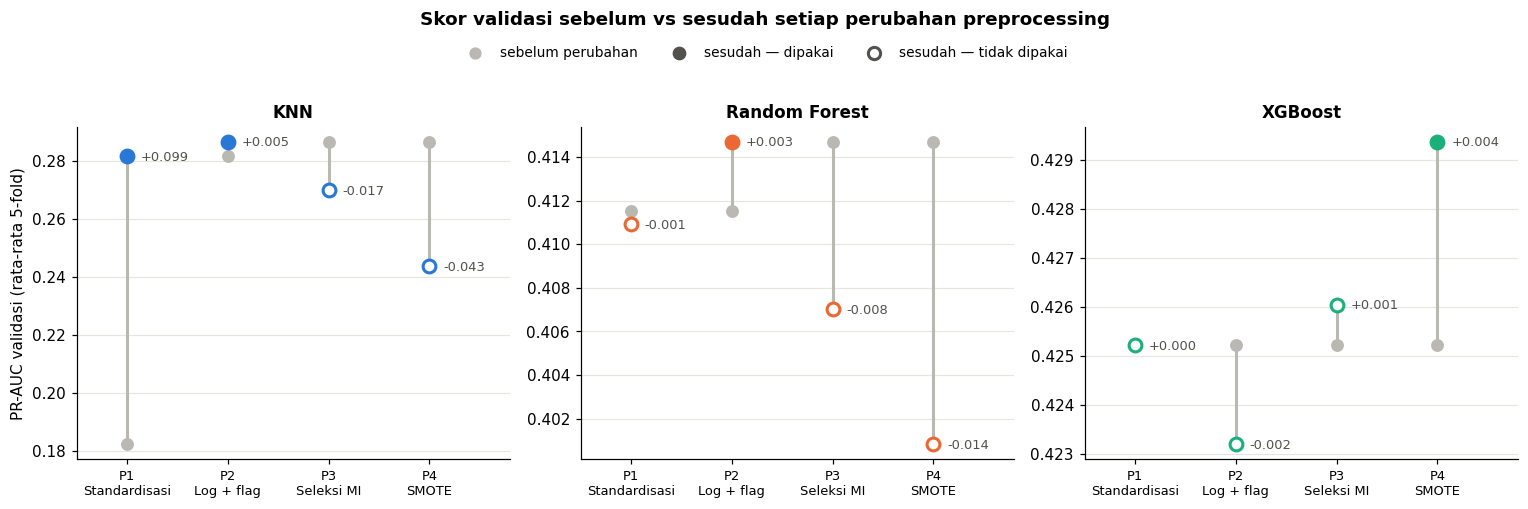

In [15]:
LABEL_LANGKAH = {"P1": "P1\nStandardisasi", "P2": "P2\nLog + flag", "P3": "P3\nSeleksi MI", "P4": "P4\nSMOTE"}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (nama, grup) in zip(axes, tabel_prepro.groupby("Model", sort=False)):
    warna = WARNA[nama]
    for x, (_, r) in enumerate(grup.iterrows()):
        dipakai = r["Keputusan"].startswith("dipakai")
        ax.plot([x, x], [r["PR-AUC sebelum"], r["PR-AUC sesudah"]], color=ABU, lw=2, zorder=1)
        ax.scatter(x, r["PR-AUC sebelum"], s=55, color=ABU, zorder=2)
        ax.scatter(x, r["PR-AUC sesudah"], s=70, zorder=3, linewidth=2,
                   color=warna if dipakai else "white", edgecolor=warna)
        ax.annotate(f"{r['Δ PR-AUC']:+.3f}", (x, r["PR-AUC sesudah"]), textcoords="offset points",
                    xytext=(9, -3), fontsize=8.5, color=TEKS)
    ax.set_xticks(range(len(grup)), [LABEL_LANGKAH[k] for k in grup["Langkah"]], fontsize=8.5)
    ax.set_xlim(-0.5, len(grup) - 0.2)
    ax.set_title(nama)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("PR-AUC validasi (rata-rata 5-fold)")
fig.legend(handles=[
    Line2D([0], [0], marker="o", ls="", color=ABU, markersize=7, label="sebelum perubahan"),
    Line2D([0], [0], marker="o", ls="", color=TEKS, markersize=8, label="sesudah — dipakai"),
    Line2D([0], [0], marker="o", ls="", markerfacecolor="white", markeredgecolor=TEKS, markeredgewidth=2, markersize=8, label="sesudah — tidak dipakai"),
], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04), fontsize=9)
fig.suptitle("Skor validasi sebelum vs sesudah setiap perubahan preprocessing", fontweight="bold", y=1.09)
plt.tight_layout()
plt.show()

**Interpretasi:**
- **KNN** paling sensitif: standardisasi **+0,099**, log + flag +0,005.
- **Random Forest & XGBoost** tidak terpengaruh scaling (pohon memotong per fitur).
- **Seleksi MI** menurunkan skor semua model → hampir semua fitur informatif.
- **SMOTE** menurunkan KNN (−0,043) & RF (−0,014), menaikkan XGBoost (+0,004).

| Model | Preprocessing terpilih | PR-AUC |
|---|---|---|
| KNN | one-hot + scaling + log & flag | 0,182 → 0,287 |
| Random Forest | one-hot + log & flag | 0,412 → 0,415 |
| XGBoost | one-hot + SMOTE | 0,425 → 0,429 |

### 3.2 Hyperparameter tuning
Preprocessing dikunci (hasil 3.1). Optimasi PR-AUC dengan CV yang sama.

| Model | Metode | Hyperparameter |
|---|---|---|
| KNN | Grid (32 kombinasi) | `n_neighbors`, `weights`, `p` |
| Random Forest | Random (20) | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` |
| XGBoost | Random (40) | `n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `gamma`, `reg_lambda`, `scale_pos_weight` |

In [16]:
RUANG_HYPERPARAMETER = {
    "KNN": ("grid", None, {
        "model__n_neighbors": [5, 15, 31, 51, 75, 101, 151, 201],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    }),
    "Random Forest": ("random", 20, {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 16, 20],
        "model__min_samples_leaf": [1, 2, 5, 10, 20],
        "model__max_features": ["sqrt", 0.3, 0.5],
        "model__class_weight": [None, "balanced_subsample"],
    }),
    "XGBoost": ("random", 40, {
        "model__n_estimators": randint(200, 1000),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(3, 9),
        "model__min_child_weight": randint(1, 11),
        "model__subsample": uniform(0.6, 0.4),          # 0,6 – 1,0
        "model__colsample_bytree": uniform(0.5, 0.5),   # 0,5 – 1,0
        "model__gamma": uniform(0, 1),
        "model__reg_lambda": loguniform(0.5, 20),
        "model__scale_pos_weight": [1, 3, 7.5],         # 7,5 ≈ rasio no : yes
    }),
}


def rapikan_param(params):
    return {k.replace("model__", ""): (float(round(v, 4)) if isinstance(v, float) else v) for k, v in params.items()}


baris_tuning, model_tuned, skor_tuned = [], {}, {}
for nama, buat_model in MODEL_KANDIDAT.items():
    jenis, n_iter, ruang = RUANG_HYPERPARAMETER[nama]
    pipe = buat_pipeline(buat_model(), **config_terbaik[nama])
    if jenis == "grid":
        search = GridSearchCV(pipe, ruang, scoring=SCORING, refit="PR-AUC", cv=CV, n_jobs=-1)
    else:
        search = RandomizedSearchCV(pipe, ruang, n_iter=n_iter, scoring=SCORING, refit="PR-AUC",
                                    cv=CV, n_jobs=-1, random_state=RANDOM_STATE)
    t0 = time.time()
    search.fit(X_train, y_train)

    i, hasil = search.best_index_, search.cv_results_
    sesudah = {m: hasil[f"mean_test_{m}"][i] for m in SCORING}
    sesudah["PR-AUC std"] = hasil["std_test_PR-AUC"][i]
    sebelum = skor_prepro[nama]
    model_tuned[nama], skor_tuned[nama] = search.best_estimator_, sesudah
    baris_tuning.append({
        "Model": nama,
        "PR-AUC sebelum (default)": sebelum["PR-AUC"], "PR-AUC sesudah (tuned)": sesudah["PR-AUC"],
        "Δ PR-AUC": sesudah["PR-AUC"] - sebelum["PR-AUC"],
        "ROC-AUC sebelum": sebelum["ROC-AUC"], "ROC-AUC sesudah": sesudah["ROC-AUC"],
        "F1 sebelum": sebelum["F1"], "F1 sesudah": sesudah["F1"],
        "Hyperparameter terbaik": rapikan_param(search.best_params_),
    })
    print(f"{nama:14s} selesai dalam {time.time() - t0:4.0f} detik ({len(hasil['params'])} kombinasi × 5 fold)")

tabel_tuning = pd.DataFrame(baris_tuning)
tabel_tuning

KNN            selesai dalam  244 detik (32 kombinasi × 5 fold)
Random Forest  selesai dalam  243 detik (20 kombinasi × 5 fold)
XGBoost        selesai dalam  346 detik (40 kombinasi × 5 fold)


,Model,PR-AUC sebelum (default),PR-AUC sesudah (tuned),Δ PR-AUC,ROC-AUC sebelum,ROC-AUC sesudah,F1 sebelum,F1 sesudah,Hyperparameter terbaik
0,KNN,0.2866,0.4078,0.1212,0.6940,0.7702,0.3096,0.2413,"{'n_neighbors': 75, 'p': 1, 'weights': 'distance'}"
1,Random Forest,0.4147,0.4466,0.0319,0.7781,0.7958,0.3264,0.3152,"{'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 16, 'class_weight': None}"
2,XGBoost,0.4294,0.4506,0.0212,0.7866,0.7993,0.3625,0.3453,"{'colsample_bytree': 0.7989, 'gamma': 0.9219, 'learning_rate': 0.013, 'max_depth': 6, 'min_child_weight': 9, 'n_estimators': 901, 'reg_lambda': 1.6602, 'scale_pos_weight': 1, 'subsample': 0.7085}"


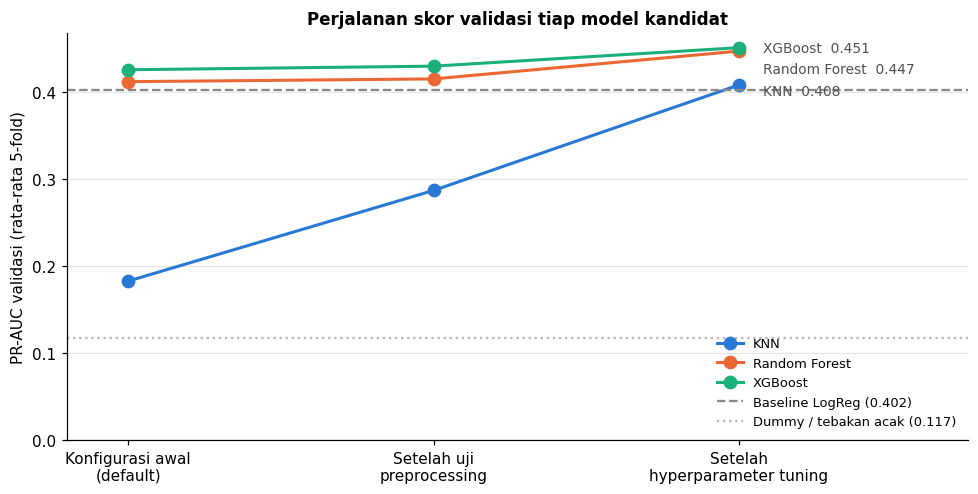

In [17]:
tahap = ["Konfigurasi awal\n(default)", "Setelah uji\npreprocessing", "Setelah\nhyperparameter tuning"]

# posisi label di ujung garis digeser agar tidak saling bertumpuk
posisi_label, batas = {}, None
for nama, v in sorted(((n, skor_tuned[n]["PR-AUC"]) for n in MODEL_KANDIDAT), key=lambda t: -t[1]):
    posisi_label[nama] = v if batas is None else min(v, batas - 0.025)
    batas = posisi_label[nama]

fig, ax = plt.subplots(figsize=(9, 4.6))
for nama in MODEL_KANDIDAT:
    nilai = [hasil_awal[nama]["PR-AUC"], skor_prepro[nama]["PR-AUC"], skor_tuned[nama]["PR-AUC"]]
    ax.plot(range(3), nilai, marker="o", markersize=8, lw=2, color=WARNA[nama], label=nama)
    ax.annotate(f"{nama}  {nilai[-1]:.3f}", xy=(2, nilai[-1]), xytext=(2.08, posisi_label[nama]),
                textcoords="data", va="center", fontsize=9, color=TEKS)
ax.axhline(hasil_awal["Baseline (LogReg)"]["PR-AUC"], color=WARNA["Baseline (LogReg)"], ls="--", lw=1.5,
           label=f"Baseline LogReg ({hasil_awal['Baseline (LogReg)']['PR-AUC']:.3f})")
ax.axhline(hasil_awal["Dummy (referensi)"]["PR-AUC"], color=ABU, ls=":", lw=1.5,
           label=f"Dummy / tebakan acak ({hasil_awal['Dummy (referensi)']['PR-AUC']:.3f})")
ax.set_xticks(range(3), tahap)
ax.set_xlim(-0.2, 2.75)
ax.set_ylim(0, None)
ax.set_ylabel("PR-AUC validasi (rata-rata 5-fold)")
ax.set_title("Perjalanan skor validasi tiap model kandidat")
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Interpretasi:**
- Kenaikan PR-AUC: **KNN +0,121**, Random Forest +0,032, XGBoost +0,021.
- KNN: k 5 → 75 membuat estimasi probabilitas lebih halus.
- RF & XGBoost: pohon dibatasi/diregularisasi; XGBoost memakai learning rate kecil (0,013) + 901 pohon.
- Setelah tuning, semua kandidat di atas baseline (0,402).

---
## 4. Pemilihan dan Evaluasi Model Terbaik

### 4.1 Pemilihan model
Dipilih **hanya dari skor validasi**; data uji belum disentuh.

In [18]:
ringkasan_validasi = pd.DataFrame(
    {"Baseline (LogReg)": hasil_awal["Baseline (LogReg)"], **{f"{n} (tuned)": skor_tuned[n] for n in MODEL_KANDIDAT}}
).T.sort_values("PR-AUC", ascending=False)

nama_terbaik = ringkasan_validasi.drop(index="Baseline (LogReg)").index[0].replace(" (tuned)", "")
model_final = model_tuned[nama_terbaik]

print(f"Model terpilih          : {nama_terbaik}")
print(f"Preprocessing           : {config_terbaik[nama_terbaik]}")
print(f"Hyperparameter          : {rapikan_param({k: v for k, v in model_final.get_params().items() if k in RUANG_HYPERPARAMETER[nama_terbaik][2]})}")
ringkasan_validasi

Model terpilih          : XGBoost
Preprocessing           : {'scaling': False, 'transform': False, 'k_fitur': None, 'smote': True}
Hyperparameter          : {'colsample_bytree': 0.7989, 'gamma': 0.9219, 'learning_rate': 0.013, 'max_depth': 6, 'min_child_weight': 9, 'n_estimators': 901, 'reg_lambda': 1.6602, 'scale_pos_weight': 1, 'subsample': 0.7085}


,PR-AUC,ROC-AUC,F1,Precision,Recall,PR-AUC std
XGBoost (tuned),0.4506,0.7993,0.3453,0.6293,0.2380,0.0115
Random Forest (tuned),0.4466,0.7958,0.3152,0.6560,0.2075,0.0137
KNN (tuned),0.4078,0.7702,0.2413,0.6885,0.1463,0.0106
Baseline (LogReg),0.4021,0.7628,0.2749,0.6446,0.1749,0.0084


**Terpilih: XGBoost**, dengan PR-AUC validasi tertinggi (**0,451 ± 0,011**) serta ROC-AUC dan F1 tertinggi. Random Forest sangat dekat (0,447); selisihnya lebih kecil dari variasi antar-fold.

Pipeline akhir: **one-hot → SMOTE → XGBoost (tuned)**.

### 4.2 Threshold keputusan
Dipilih dari prediksi *out-of-fold* data latih (F1 maksimum), bukan dari data uji. Cara yang sama dipakai untuk baseline.

In [19]:
def threshold_f1_terbaik(pipeline):
    proba_oof = cross_val_predict(pipeline, X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    precision, recall, thr = precision_recall_curve(y_train, proba_oof)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    i = np.argmax(f1[:-1])
    return thr[i], f1[i]


thr_final, f1_oof_final = threshold_f1_terbaik(model_final)
thr_base, f1_oof_base = threshold_f1_terbaik(pipeline_baseline)
print(f"{nama_terbaik:18s}: threshold = {thr_final:.3f}  (F1 validasi out-of-fold = {f1_oof_final:.4f})")
print(f"{'Baseline (LogReg)':18s}: threshold = {thr_base:.3f}  (F1 validasi out-of-fold = {f1_oof_base:.4f})")

XGBoost           : threshold = 0.201  (F1 validasi out-of-fold = 0.4863)
Baseline (LogReg) : threshold = 0.191  (F1 validasi out-of-fold = 0.4425)


### 4.3 Evaluasi pada data uji
Model akhir dan baseline diuji **sekali** pada data uji.

In [20]:
def evaluasi_test(pipeline, threshold):
    proba = pipeline.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    skor = {
        "PR-AUC": average_precision_score(y_test, proba), "ROC-AUC": roc_auc_score(y_test, proba),
        "F1": f1_score(y_test, pred), "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred), "Akurasi": accuracy_score(y_test, pred), "Threshold": threshold,
    }
    return proba, pred, skor


pipeline_baseline.fit(X_train, y_train)
proba_final, pred_final, test_final = evaluasi_test(model_final, thr_final)
proba_base, pred_base, test_base = evaluasi_test(pipeline_baseline, thr_base)

tabel_test = pd.DataFrame({f"{nama_terbaik} (final)": test_final, "Baseline (LogReg)": test_base}).T
display(tabel_test)

validasi_vs_uji = pd.DataFrame({
    "PR-AUC validasi (CV)": [skor_tuned[nama_terbaik]["PR-AUC"], hasil_awal["Baseline (LogReg)"]["PR-AUC"]],
    "PR-AUC data uji": [test_final["PR-AUC"], test_base["PR-AUC"]],
}, index=tabel_test.index)
validasi_vs_uji["selisih"] = validasi_vs_uji["PR-AUC data uji"] - validasi_vs_uji["PR-AUC validasi (CV)"]
display(validasi_vs_uji)

print(f"Classification report — {nama_terbaik} (threshold {thr_final:.3f}) pada data uji:\n")
print(classification_report(y_test, pred_final, target_names=["no", "yes"], digits=4))

,PR-AUC,ROC-AUC,F1,Precision,Recall,Akurasi,Threshold
XGBoost (final),0.4625,0.8085,0.4994,0.4592,0.5473,0.8716,0.2007
Baseline (LogReg),0.4111,0.7717,0.4487,0.4448,0.4527,0.8698,0.1913


,PR-AUC validasi (CV),PR-AUC data uji,selisih
XGBoost (final),0.4506,0.4625,0.0119
Baseline (LogReg),0.4021,0.4111,0.0090


Classification report — XGBoost (threshold 0.201) pada data uji:

              precision    recall  f1-score   support

          no     0.9384    0.9146    0.9264      7985
         yes     0.4592    0.5473    0.4994      1058

    accuracy                         0.8716      9043
   macro avg     0.6988    0.7309    0.7129      9043
weighted avg     0.8824    0.8716    0.8764      9043



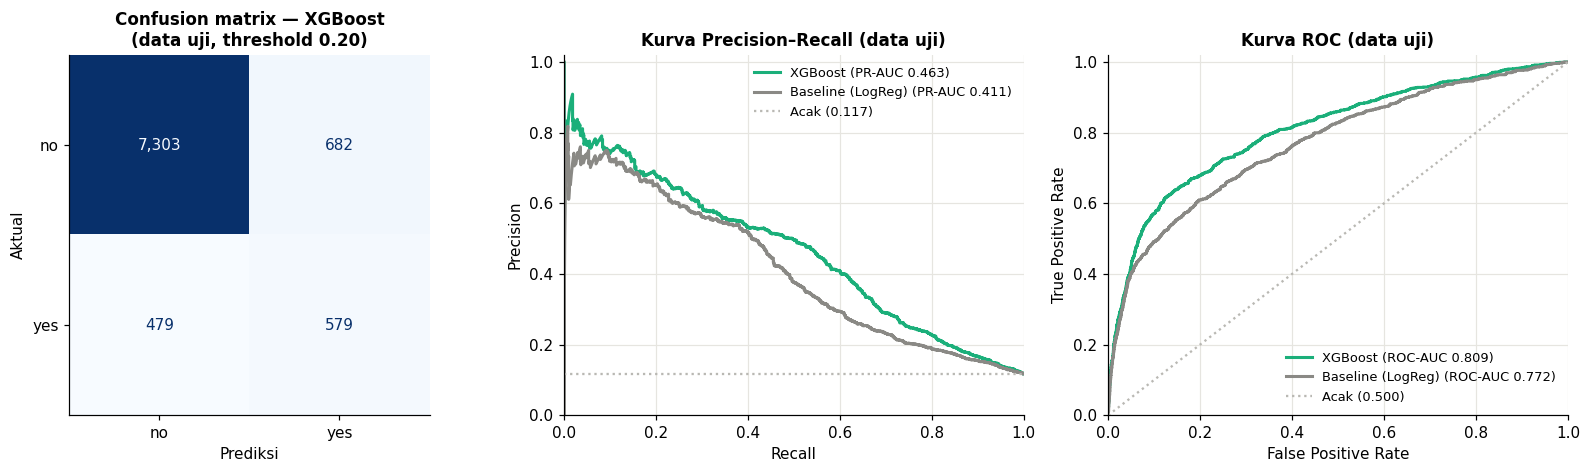

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final), display_labels=["no", "yes"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title(f"Confusion matrix — {nama_terbaik}\n(data uji, threshold {thr_final:.2f})")
axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual"); axes[0].grid(False)

for nama, proba, warna in [(nama_terbaik, proba_final, WARNA[nama_terbaik]),
                           ("Baseline (LogReg)", proba_base, WARNA["Baseline (LogReg)"])]:
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(r, p, color=warna, lw=2, label=f"{nama} (PR-AUC {average_precision_score(y_test, proba):.3f})")
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[2].plot(fpr, tpr, color=warna, lw=2, label=f"{nama} (ROC-AUC {roc_auc_score(y_test, proba):.3f})")
axes[1].axhline(y_test.mean(), color=ABU, ls=":", lw=1.5, label=f"Acak ({y_test.mean():.3f})")
axes[2].plot([0, 1], [0, 1], color=ABU, ls=":", lw=1.5, label="Acak (0.500)")
axes[1].set(title="Kurva Precision–Recall (data uji)", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
axes[2].set(title="Kurva ROC (data uji)", xlabel="False Positive Rate", ylabel="True Positive Rate", xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend(fontsize=8.5); axes[2].legend(fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()

### 4.4 Fitur paling berpengaruh
*Permutation importance*: penurunan PR-AUC saat satu fitur diacak.

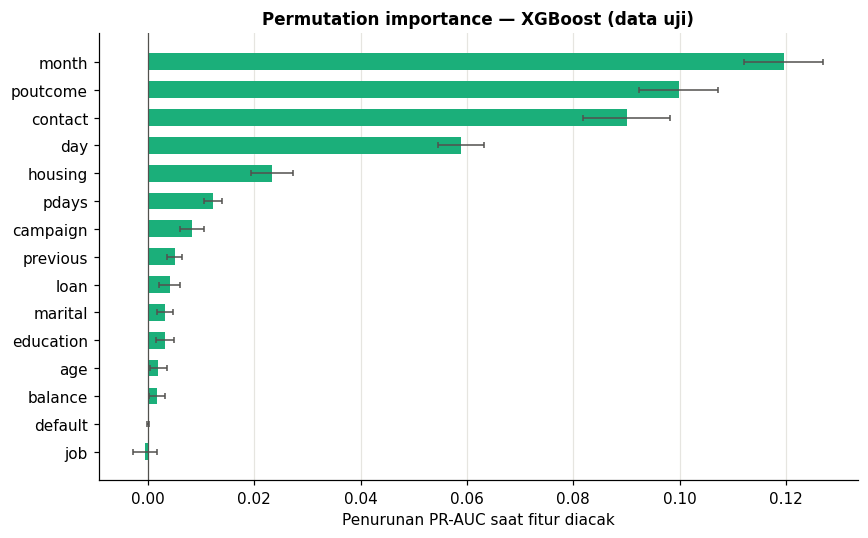

In [22]:
imp = permutation_importance(model_final, X_test, y_test, scoring="average_precision",
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
tabel_imp = pd.DataFrame({"penurunan PR-AUC (rata-rata)": imp.importances_mean, "std": imp.importances_std},
                         index=X_test.columns).sort_values("penurunan PR-AUC (rata-rata)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tabel_imp.index, tabel_imp.iloc[:, 0], xerr=tabel_imp["std"], color=WARNA[nama_terbaik],
        height=0.6, error_kw={"ecolor": TEKS, "lw": 1, "capsize": 2})
ax.axvline(0, color=TEKS, lw=0.8)
ax.set_xlabel("Penurunan PR-AUC saat fitur diacak")
ax.set_title(f"Permutation importance — {nama_terbaik} (data uji)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Interpretasi:** `month`, `poutcome`, `contact`, dan `day` paling berpengaruh → waktu kontak & riwayat kampanye lebih penting daripada demografi (sesuai EDA 1.4). Pengaruh `month`/`day` terkait periode 2008–2010, perlu dipantau.

### 4.5 Makna bisnis
Jika hanya X% nasabah ber-skor tertinggi yang ditelepon, berapa persen calon pelanggan yang terjangkau?

,nasabah ditelepon,% nasabah 'yes' tertangkap,tingkat konversi,lift vs acak
Top 10% ditelepon,904,44.5%,52.1%,4.45×
Top 20% ditelepon,"1,809",63.4%,37.1%,3.17×
Top 30% ditelepon,"2,713",71.9%,28.1%,2.40×
Top 50% ditelepon,"4,522",84.2%,19.7%,1.68×


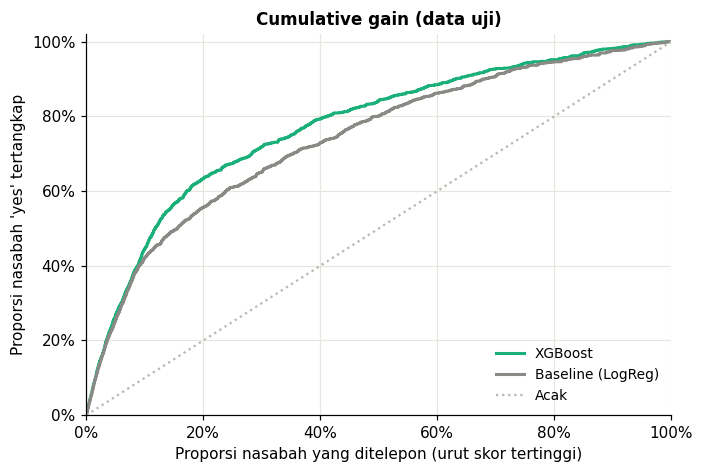

In [23]:
def tabel_gain(proba, persen=(0.1, 0.2, 0.3, 0.5)):
    urut = y_test.to_numpy()[np.argsort(-proba)]
    baris = {}
    for p in persen:
        n = int(round(p * len(urut)))
        baris[f"Top {p:.0%} ditelepon"] = {
            "nasabah ditelepon": n,
            "% nasabah 'yes' tertangkap": urut[:n].sum() / urut.sum(),
            "tingkat konversi": urut[:n].mean(),
            "lift vs acak": urut[:n].mean() / urut.mean(),
        }
    return pd.DataFrame(baris).T


gain_final = tabel_gain(proba_final)
tampil = gain_final.copy()
tampil["nasabah ditelepon"] = tampil["nasabah ditelepon"].map("{:,.0f}".format)
for kol in ["% nasabah 'yes' tertangkap", "tingkat konversi"]:
    tampil[kol] = tampil[kol].map("{:.1%}".format)
tampil["lift vs acak"] = tampil["lift vs acak"].map("{:.2f}×".format)
display(tampil)

fig, ax = plt.subplots(figsize=(6.5, 4.4))
for nama, proba, warna in [(nama_terbaik, proba_final, WARNA[nama_terbaik]),
                           ("Baseline (LogReg)", proba_base, WARNA["Baseline (LogReg)"])]:
    urut = y_test.to_numpy()[np.argsort(-proba)]
    ax.plot(np.arange(1, len(urut) + 1) / len(urut), np.cumsum(urut) / urut.sum(), color=warna, lw=2, label=nama)
ax.plot([0, 1], [0, 1], color=ABU, ls=":", lw=1.5, label="Acak")
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(xlabel="Proporsi nasabah yang ditelepon (urut skor tertinggi)", ylabel="Proporsi nasabah 'yes' tertangkap",
       title="Cumulative gain (data uji)", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Hasil:** menelepon **20%** nasabah teratas → **63,4%** calon pelanggan terjangkau, konversi 37,1% (**3,2×** menelepon acak).

---
## 5. Kesimpulan
1. Klasifikasi biner tidak seimbang; metrik **PR-AUC**; `duration` dibuang (leakage).
2. Efek preprocessing bergantung algoritma: scaling + log penting untuk KNN, tidak untuk model pohon; seleksi MI tidak membantu; SMOTE hanya membantu XGBoost.
3. Tuning menaikkan semua model (terbesar KNN +0,121).
4. **Terbaik: one-hot + SMOTE + XGBoost (tuned)**, PR-AUC validasi 0,451.
5. **Data uji:** PR-AUC **0,463**, ROC-AUC **0,809**, F1 **0,499**, lebih baik dari baseline (0,411 / 0,772 / 0,449); tidak ada indikasi overfitting.
6. **Bisnis:** menelepon 20% nasabah teratas menjangkau 63% calon pelanggan.

**Keterbatasan & saran:** validasi berbasis waktu, SMOTENC untuk fitur kategorikal, tuning lebih luas, ensemble XGBoost + Random Forest.